# Chapter 1 - Random signals



## By Ludovic Moreau and Pierre Boué 

<div style="page-break-after: always;"></div>



## What is a random signal?

Contrary to a deterministic signal, which can be characterized by parameters such as a frequency, amplitude...,  a random signal cannot be predicted from a knowledge of values at other past instants. The characteristics of
random signals can be described only in terms of probabilities. 

A true random process is, however, complicated to come by in nature. There is a common idea that noise is a true random signal. But what is noise? For example, let us have a look at some seismic "noise" recorded by a geophone. 
<img src="./Lecture_PDFs/seismic_noise.png">
This "noise" appears to have different characteristics, depending on which of the three channels it is observed. For example, on the horizontal channels (i.e. north and east), some impulsive events are visible at the beginning of the recordings. 

Noise is generated by a source that follows the laws of physics. In essence, it cannot be truly random, since, given the same initial and boundary conditions, it will produce the same result, and is therefore predictable. 

With current knownledge of Physics, the only truly random processes are those governed by quantum Physics.

In the context of this course, we will therefore use the term "random" to describe signals that reflect a phenomenon whose unpredictability is due solely to a lack of understanding or knowledge.

## Full vs partial description of a random signal

In the following, a random signal will be denoted as $X(t,R)$, to express the fact that it depends on the time, $t$, and on its realization, $R$. 

To fully describe a random signal, it must be known at each time and for each realization, for example:

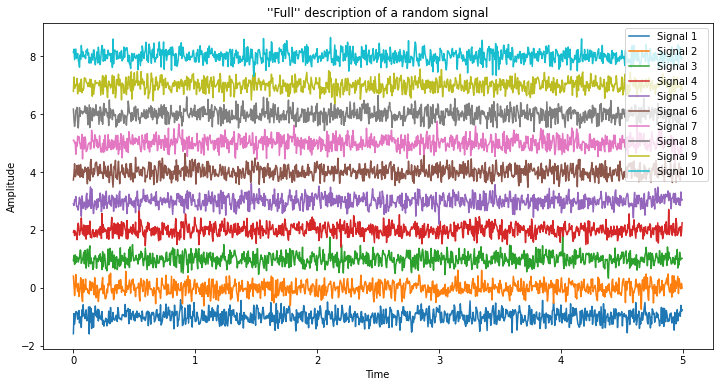

In [59]:
import numpy as np
import matplotlib.pyplot as plt

# Number of signals
num_signals = 10

# Signal length
fe = 200
time = np.arange(0,5,1/fe)
signal_length = len(time)

# Generate random signals
signals = np.random.randn(signal_length, num_signals)

# Create a new figure
plt.figure(figsize=(12, 6))

# Plot each signal
for i in range(num_signals):
    plt.plot(time,i-1+signals[:, i]/5, label=f"Signal {i+1}")

# Add legend
plt.legend()

# Set plot title and labels0
plt.title("''Full'' description of a random signal")
plt.xlabel("Time")
plt.ylabel("Amplitude")

# Show the plot
plt.show()

Of course, the full description of a random signal is generally not possible, and one may access only to :

- one realization of the random process, when $R$ is fixed, $X(t,R_k)$
- a "classical" random variable, when $t$ is fixed, $X(t_i,R)=X(t_i)$

When $X(t,R)$ is known at two instants, $t_1$ and $t_2$, the statistical link between the two corresponding random variables is given by the Bravais-Pearson correlation coefficient:

\begin{equation}
C_{XX}(t_1,t_2) = \frac{\text{Cov}(X_1,X_2)}{\sigma_1 \sigma_2},
\end{equation}

where $\sigma_1$ and $\sigma_2$ are the standard deviations of $X(t_1)$ and $X(t_2)$, and $\text{Cov}$ is the covariance between the two realizations:

\begin{equation}
\text{Cov}(X(t_1),X(t_2)) = E \left[   \left(X(t_1)-E[X(t_1)] \right)  \left(X(t_2)-E[X(t_2)] \right) \right] = E\left[ X(t_1) X(t_2)   \right] - E[X(t_1)]E[X(t_2)]
\end{equation}

Unless two random variables $X(t_1)$ and $X(t_2)$ have no covariance, i.e. $\text{Cov}(X(t_1),X(t_2)) =0$, the joint density of probability of $X(t_1)$ and $X(t_2)$, $P_{X(t_1) X(t_2)}(x_1,x_2)$, cannot be calculated as the product between $P_{X(t_1)}$ and $P_{X(t_2)}$.

The behavior of a random signal is generally not identical at any 2 instants. However, it can be convenient to introduce the notion of stationarity to describe time-invariant behaviors. 

## Stationarity
### Strict-sense stationarity

A random signal is said to be stationary in the strict sense if the joint probability densities of all random variables are independent of time:

\begin{equation}
P_{X(t_1),X(t_2),...,X(t_k)}= P_{X(t_1-\tau),X(t_2-\tau),...,X(t_k-\tau)}. 
\end{equation}

In this case, the random variable at time $t_k$ can be deduced from that measured at t=0, because for any $\tau$:
\begin{equation}
P_{X(t_1)}= P_{X(t_1-\tau)}=...=P_{X(0)}. 
\end{equation}

Therefore, if a random signal is stationary in the strict sense, then all its moments are independent of time:
\begin{equation}
E[X^n(t_1)]= E[X^n(t_2)]=...=E[X^n(t_k)], \forall  n
\end{equation}

The condition of stationarity in the strict sense is, however, difficult to achieve in practice, as the probability density of all random variables is not known.


### Weak or wide-sense stationarity (WSS)

Stationarity in the weak sense is easier to verify in practice. A random signal is said to be stationary in the weak sense if the random variables:

- are stationary at the first order, i.e. $E[X(t_1)]=...=E[X(t_k)]= \mu_k$
- are stationary at the second order, i.e. $\text{Var}(X(t_1))=...=\text{Var}(X(t_k))$
- have a constant autocovariance, i.e. $\forall$ $t_1, t_2$  and $\tau$, $\text{Cov}[X(t_1+\tau),X(t_2+\tau)]=\text{Cov}[X(t_1),X(t_2)]$

Another way of seeing the third condition of weak-sense stationarity is to remark that 
$\text{Cov}[X(t_1),X(t_2)]=\frac{1}{\sigma_X^2}E[X(t_1-t_2)X(0)]-\frac{\mu_X^2}{\sigma_X^2}=\frac{1}{\sigma_X^2}E[X(0)X(t_2-t_1)]-\frac{\mu_X^2}{\sigma_X^2}= \frac{1}{\sigma_X^2}E[X(t)X(t-\tau)]-\frac{\mu_X^2}{\sigma_X^2}$, where $\tau = t_1-t_2$.

Hence when a signal is stationary in the weak sense (and therefore also in the strict sense), the covariance function becomes proportional to the autocorrelation function.


### Example 1

We consider the following random signal

$s(t,R) = \cos(\omega(R) t + \phi(R))$, where $\omega(R)$ follows a probability density denoted by $f(\omega)$, and $\phi(R)$ follows a uniform probability density in $[0,2\pi]$.

$s(t,R)$ is a function of two random variables. Hence its expected value is calcualted such that:

\begin{equation}
E[s] = \int_{-\infty}^{\infty} \int_{0}^{2\pi} \frac{1}{2\pi}f(\omega)\cos(\omega t + \phi) d\phi d\omega
     = \int_{-\infty}^{\infty}f(\omega) \frac{1}{2\pi} \int_{0}^{2\pi}\cos(\omega t + \phi) d\phi d\omega
     =0
\end{equation}

The mean of $s(t,R)$ is constant, so this random signal is stationary at the first order. 



Let us evaluate the covariance between two realizations of $s$ at instants $t_1$ and $t_2$:

\begin{equation}
\text{Cov}[s(t_1),s(t_2)]= \int_{-\infty}^{\infty} \int_{0}^{2\pi} f(\omega)\cos(\omega t_1 + \phi)\cos(\omega t_2 + \phi) d\phi d\omega
= \int_{-\infty}^{\infty} f(\omega)  \frac{1}{2}\left[ \int_{0}^{2\pi}  \cos(\omega (t_1-t_2)) + \cos(\omega (t_1+t_2)+2\phi)d\phi \right]d\omega = \int_{-\infty}^{\infty} f(\omega) \pi\cos(\omega (t_1-t_2))d\omega.
\end{equation}
This is only a function of the time delay $\tau = t_1-t_2$. Hence this signal is stationary in the weak sense. 

### Example 2

Prove that if a signal is WSS, then its covariance is stationary.

#### Solution

\begin{equation}
\text{Cov}(X(t_1),X(t_2)) = E\left[ X(t_1) X(t_2)   \right] - E[X(t_1)]E[X(t_2)] = R_{XX}(t_1,t_2) - \mu_X^2 = R_{XX}(t_1 - t_2) - \mu_X^2.
\end{equation}
Hence its covariance depends only on $t_1 - t_2$. 

### Example 3
Let $X(t) = A\cos(\omega t)+B\sin(\omega t)$, where $A$ and $B$ are independent random variables, each of which take values -2 and 1 with probabilities 1/3 and 2/3.
Prove that $X(t)$ is WSS but not strict sent stationary.

#### Solution


## Ergodicity

Ergodicity is a property that describes how the statistical behavior of a signal evolves over time or over a realization. An ergodic signal is one that behaves statistically in a way that is representative of its entire duration. In other words, a random signal is said to be ergodic if the ensemble average equals the time average. 

If a random signal is ergodic, then its statistical properties, such as mean, variance, and autocorrelation, are constant or converge to constant values as the observation time increases. As such, if one samples different time segments and compute statistics, those statistics should be representative of the overall signal. Consequently, the long-term behavior of an ergodic signal can be inferred from its short-term behavior.

### Example 1 (continued)

Let us examine the random signal from example 1, $s(t,R) = \cos(\omega(R) t + \phi(R))$, with the extra-assumption that the probability density for $f(\omega)$ is a gaussian with mean $40\pi$ rad/s  and standard deviation $20\pi$ rad/s. 





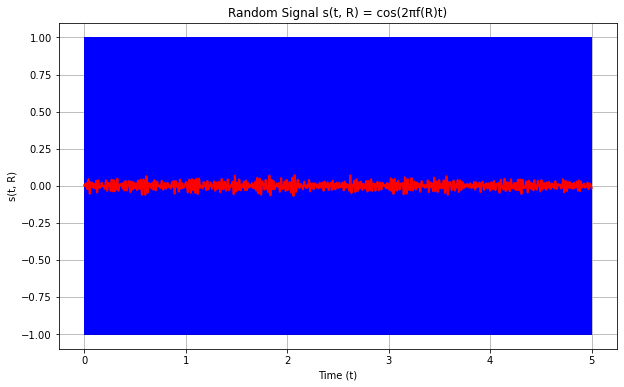

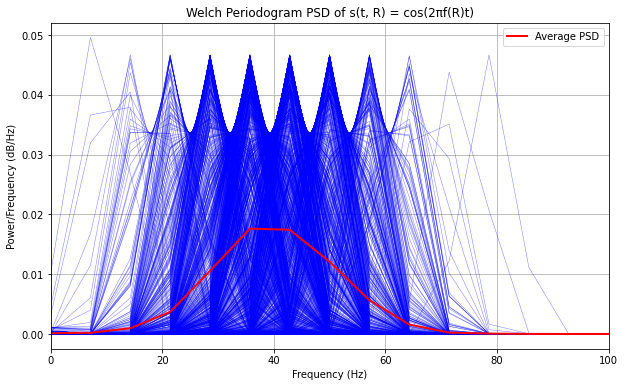

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch
fe = 1000  # sampling frequency
# Define the parameters
mean_f = 40  # Mean of the Gaussian distribution for f(R)
std_dev_f = 10  # Standard deviation of the Gaussian distribution for f(R)
t = np.arange(0, 5, 1/fe)
num_samples = 1000  # Number of random samples

# Generate random values for f(R) and phi(R)
f_R_samples = np.random.normal(mean_f, std_dev_f, num_samples)
phi_min = 0
phi_max = 2 * np.pi
phi_R = np.random.uniform(phi_min, phi_max, num_samples)

# Initialize an empty array to store the signal
s_t_R = np.zeros((num_samples, len(t)))
# Generate the signal for each random sample of f(R) and store them
for i, f_R in enumerate(f_R_samples):
    signal = np.cos(2 * np.pi * f_R * t + phi_R[i])
    s_t_R[i, :] = signal

# Calculate the average signal over all samples
average_signal = np.mean(s_t_R, axis=0)

# Plot the individual signals and the average signal
plt.figure(figsize=(10, 6))
for i in range(num_samples):
    plt.plot(t, s_t_R[i, :], alpha=0.5, linewidth=0.5, color='blue')
plt.plot(t, average_signal, linewidth=2, color='red', label='Average Signal')
plt.title('Random Signal s(t, R) = cos(2πf(R)t)')
plt.xlabel('Time (t)')
plt.ylabel('s(t, R)')

plt.grid(True)
plt.show()

frequencies, welch_psd = welch(s_t_R, axis=1, fs=fe, nperseg=140)

# Calculate the average Welch PSD
average_psd = np.mean(welch_psd, axis=0)

# Plot the individual PSDs and the average PSD
plt.figure(figsize=(10, 6))
for i in range(num_samples):
    plt.plot(frequencies, welch_psd[i, :], alpha=0.5, linewidth=0.5, color='blue')
plt.plot(frequencies, average_psd, linewidth=2, color='red', label='Average PSD')
plt.title('Welch Periodogram PSD of s(t, R) = cos(2πf(R)t)')
plt.xlabel('Frequency (Hz)')
plt.xlim(0, 100)
plt.ylabel('Power/Frequency (dB/Hz)')
plt.legend()
plt.grid(True)
plt.show()

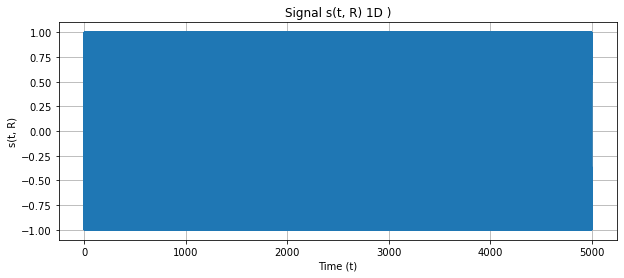

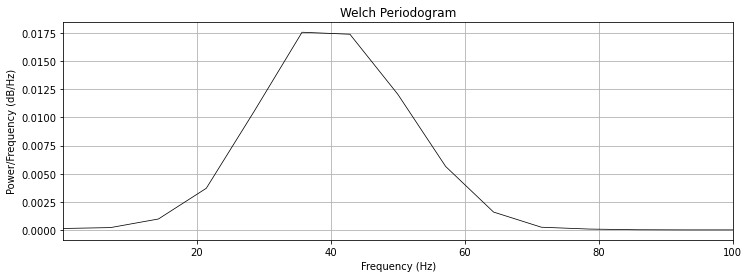

In [142]:
long_signal = s_t_R.reshape(1, -1)  # Reshape to (1, 5000000)
t_long = np.arange(0, 5 * 1000, 1/fe)
# Plot the concatenated signal
plt.figure(figsize=(10, 4))
plt.plot(t_long, long_signal[0], label='Concatenated Signal')
plt.title('Signal s(t, R) 1D )')
plt.xlabel('Time (t)')
plt.ylabel('s(t, R)')
plt.grid(True)
plt.show()


from scipy.signal import welch
frequencies, welch_psd = welch(long_signal[0], fs=fe, nperseg=140)
plt.figure(figsize=(12, 4))
plt.plot(frequencies, welch_psd,'k',lw=0.75)
plt.xlim(0.1, 100) 
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power/Frequency (dB/Hz)')
plt.title('Welch Periodogram')
plt.grid()
plt.show()


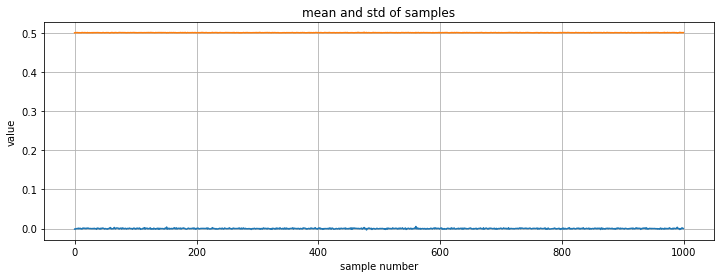

the mean of the long signal is 2.3347287591845614e-05
the variance of the long signal is 0.4999997217450156


In [171]:
means = np.zeros(num_samples)
stds = np.zeros(num_samples)
for i, f_R in enumerate(s_t_R):
    means[i] = np.mean(s_t_R[i,:])
    stds[i] = np.var(s_t_R[i,:])
    
plt.figure(figsize=(12, 4))
plt.plot(means)
plt.plot(stds)
plt.xlabel('sample number')
plt.ylabel('value')
plt.title('mean and std of samples')
plt.grid()
plt.show()

mean_str = str(np.mean(long_signal))
variance_str = str(np.var(long_signal))

print('the mean of the long signal is ' + mean_str)
print('the variance of the long signal is ' + variance_str)

## Signal-to-noise ratio

Assume a random signal made of a deterministic signal, $s$, with power $P$ corrupted by some noise, $n$ with average $\mu$ and a variance $\sigma^2$, such that:
\begin{equation}
r(t) = s(t) + n(t).
\end{equation}

The signal-to-noise ratio is calcualted from the ratio between the power of the signal and that of the noise. It is expressed in dB, such that:

\begin{equation}
\text{SNR} = 10\text{log}_\text{10}\ ( \frac{P}{\sigma^2 })
\end{equation}

We further assume that we can obtain M realizations of this random signal: 
\begin{equation}
r_m(t) = s(t) + n_m(t), m=1,...,M 
\end{equation}
where all realizations of noise are independent. If we average the noise realizations, we obtain the averaged noise $n_{avg}$
\begin{equation}
n_\text{avg}(t) = \frac{1}{M}\sum_{m=1}^M n_m(t)
\end{equation}

The esperance of $n_\text{avg}$ is $\mu_{n_\text{avg}(t)}=E[\frac{1}{M}\sum_{m=1}^M n_m(t)] = \frac{1}{M}\sum_{m=1}^M E[n_m(t)]=\mu$.

/!\ The variance of $n_\text{avg}$ is $\sigma_{n_T}= \frac{1}{M^2}\sum_{m=1}^M \sigma_m^2=\frac{\sigma2}{M}$ because the noise realisations are independent, so their covariances are zero. In that particular case the variance of the sum is the sum of the variances <a name="cite_ref-1"></a>[<sup>[1]</sup>](#cite_note-1)

Consequently, by averaging $M$ realizations of $r$, noise power reduces proportionnaly to 1/M (which also means noise amplitude reduces proportionnaly to $1/\sqrt M$), and the resulting SNR becomes
\begin{equation}
\text{SNR}_\text{avg} = 10\text{log}_\text{10}\ (M \frac{P}{\sigma^2 })
\end{equation}




<a name="cite_note-1"></a>1. [^](#cite_ref-1), the variance of the sum of two random variables is
\begin{equation}
\text{Var}(X+Y)= E\left[ \left( (X+Y) -E[X+Y]  \right)^2\right] \\
= E\left[ \left( (X-E[X]) +(Y-E[Y]) \right)^2\right]\\
= E\left[ \left( X-E[X] \right)^2\right] +E\left[ \left( Y-E[Y] \right)^2\right] +E[2(X-E[X])(Y-E[Y])] \\
= \text{Var}(X)+\text{Var}(Y)+ 2\text{Cov}(X,Y)
\end{equation} 





## Power Spectral Density
For a a random signal, calculating a Fourier spectrum is ambiguous, since by essence it should contain every frequency that are all activated at random times and random amplitudes. Hence, from a physical point of view, projecting a random signal on a sinus is not appropriate since every sinus that composes the random signal is not "continuous" and has random amplitudes. Moreover, from a mathematical point of view, a random signal has infinite energy, so its Fourier transform is not finite. 

In the context of a random signal as defined above, one may calculate the statiscital emergence of a signal's energy around a given frequency, aslo known as the **power spectral density** (PSD). Its unit is in W/Hz. It is analogous to the probability density function of a random variable.

Reminder: the power of a signal, s(t), is defined as
$$
P=\lim_{{T \to \infty}} \frac{1}{T}\int_{{-T/2}}^{{T/2}} |s^2(t)| \ dt.
$$
Thanks to Parceval's theorem, this can also be expressed in the frequency domain such that:
$$
P=\lim_{{T \to \infty}} \frac{1}{T}\int_{{-\infty}}^{{\infty}} |\hat{s}^2(f)| \, df= \int_{{-\infty}}^{{\infty}} \lim_{{T \to \infty}}\frac{1}{T}|\hat{s}^2(f)| \, df,
$$
where the hat expresses the Fourier transform of the variable.

By analogy with the probability density function, $p$, of a random variable $X$: $P(x_1 \leq X \leq x_2) = \int_{x_1}^{x_2} p(x) dx$, one can define the PSD of a random signal, $X$, such that 

\begin{equation}
\text{PSD}(X) = \lim_{{T \to \infty}}\frac{1}{T}|\hat{X}^2(f)|  \tag{1}
\end{equation}
{eq}'eqn_DSP1' is the definition

Remark 1: note that $|\hat{X}^2(f)|$ is also the Fourier transform of the convolution product between $s^*(t)$ and $s(t)$: 
\begin{equation}
\lim_{{T \to \infty}}\frac{1}{T}|\hat{X}^2(f)|  = \int_{{-\infty}}^{{\infty}} \left[ \lim_{{T \to \infty}}\frac{1}{T}\int_{{-\infty}}^{{\infty}} X^*(t-\tau)X(t) \, dt \right]  e^{-2i \pi f \tau }\, d\tau. 
\end{equation}

Remark 2: If a random variable is stationary and ergodic, then the ergodic theorem states that time averages are equal to the ensemble averages, that is, the esperance of the variable:

\begin{equation}
\lim_{{T \to \infty}}\frac{1}{T}\int_{{-\infty}}^{{\infty}} X^*(t-\tau)X(t) dt = E[X^*(t-\tau).X(t)], 
\end{equation}
which is also the autocorrelation of X, which we denote by $C_{XX}(\tau)$.  

Hence if we assume that the random signal is stationary and ergodic, then its DSP is the Fourier transform of its autocorrelation:

\begin{equation}
\text{PSD}(X) = \text{TF}[{C}_{XX}(\tau)]. 
\end{equation}

**This is known as the Wiener-Khintchine theorem.** 

### Estimating the PSD

#### Periodogram

The most basic method to estimate a PSD consists of applying equation (1) to the signal, by calculating the square of the Fourier spectrum obtained with a discrete Fourier transorm.
If the signal has a variance $\sigma^2$, then the estimated 

(1e-05, 1000)

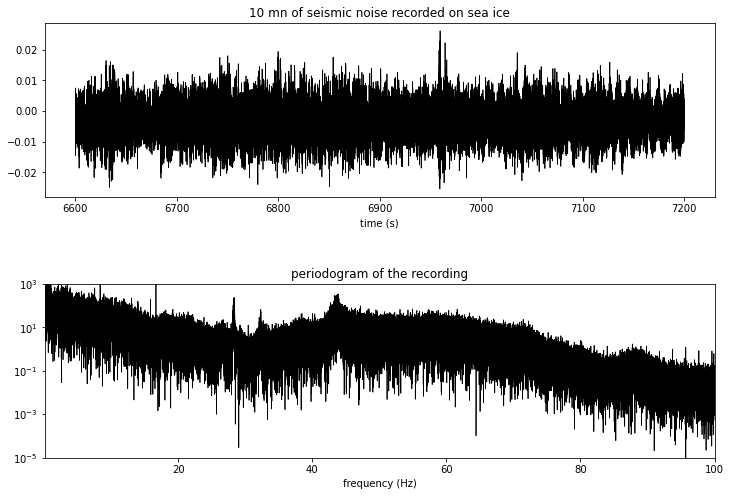

In [163]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import fft as fft

trace = np.load('data.npz')

# Retrieve the arrays from the loaded data
time = trace['array1']
fe = int(1/(time[1]-time[0]))
data1 = trace['array2']
data2 = trace['array3']
dataz = trace['array4']

freq = np.linspace(-fe/2,fe/2,len(time))
spect = np.fft.fftshift(np.fft.fft(dataz)) 
periodogram = np.square(np.abs(spect))

fig0, ax0 = plt.subplots(2,1, figsize=(12, 8), facecolor='w', edgecolor='k')
fig0.subplots_adjust(hspace = 0.5, wspace=.5)
ax0[0].plot(time,dataz,'k',lw=0.75); 
ax0[0].set_title('10 mn of seismic noise recorded on sea ice')
ax0[0].set_xlabel('time (s)')
ax0[1].semilogy(freq,periodogram,'k',lw=0.75); 
ax0[1].set_title('periodogram of the recording')
ax0[1].set_xlabel('frequency (Hz)')
ax0[1].set_xlim(0.1, 100)  
ax0[1].set_ylim(1e-5, 1000)


Number of rows: 15
Number of columns: 20000


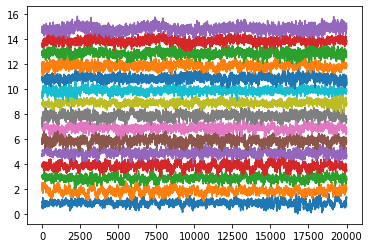

In [167]:
def create_segmented_array(vector, M, N):
    vector_length = len(vector)
    
    if M * N > vector_length:
        raise ValueError("M * N should not be greater than the length of the vector.")
    
    segmented_array = []
    for i in range(M):
        start_idx = i * N
        end_idx = start_idx + N
        segment = vector[start_idx:end_idx]
        segmented_array.append(segment)
    
    return segmented_array

seg_len = 15

N = int(len(time)/seg_len)
M = int(len(time)/N)
result = (create_segmented_array(dataz, M, N))

num_rows = len(result)
num_columns = len(result[0]) if num_rows > 0 else 0

print("Number of rows:", num_rows)
print("Number of columns:", num_columns)

k = 0
for row in result:
    k = k+1
    plt.plot(row/max(abs(row))+k)
    
    
def create_segments(larger_time_series, M, N):
    if M * N > len(larger_time_series):
        raise ValueError("M * N should be less than or equal to the length of the larger time series.")

    segments_array = [larger_time_series[i:i+N] for i in range(0, M*N, N)]
    return segments_array


seg_len = 15
seg_time = np.arange(0, seg_len, 1.0 / fe)
M = int(len(time)/seg_len/fe)
N = int(len(time)/M)



segments = create_segments(dataz, M, N)




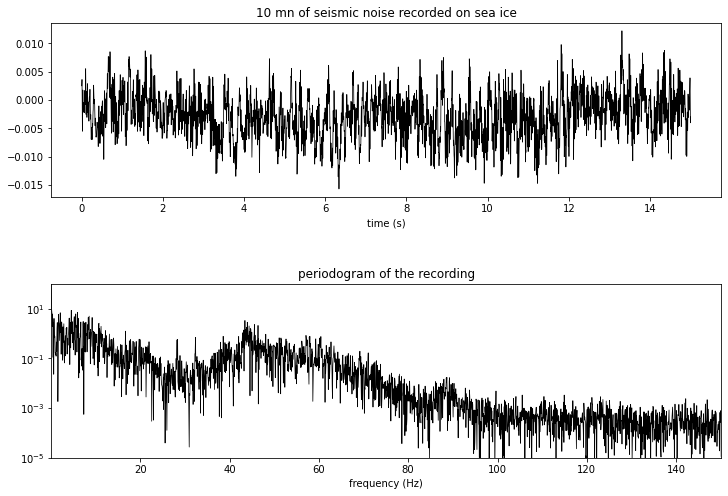

In [168]:
from IPython.display import clear_output
import time
spect = np.zeros((M, N),dtype=complex)
freq = np.linspace(-fe/2,fe/2,len(seg_time))
periodogram = np.zeros((M, N))
fig0, ax0 = plt.subplots(2,1, figsize=(12, 8), facecolor='w', edgecolor='k')
fig0.subplots_adjust(hspace = 0.5, wspace=.5)
for k in range(M):
    ax0[0].clear()  # Clear the first subplot
    ax0[1].clear() 
    spect[k,:]= np.fft.fftshift(np.fft.fft(segments[k])) 
    periodogram[k,:] = np.square(np.abs(spect[k,:]))
    #periodogram[k,:] = 20*np.log10(periodogram[k,:]/np.max(np.abs(periodogram[k,:])))  
    ax0[0].cla()  # Clear subplot 1
    ax0[1].cla()  # Clear subplot 2
    ax0[0].plot(seg_time,segments[k],'k',lw=0.75); 
    ax0[0].set_title('10 mn of seismic noise recorded on sea ice')
    ax0[0].set_xlabel('time (s)')
    ax0[1].semilogy(freq,periodogram[k,:],'k',lw=0.75); 
    ax0[1].set_xlim(0.1, 150)  # Set x-axis limits from 0 to 6
    ax0[1].set_ylim(1e-5, 1e2)
    ax0[1].set_title('periodogram of the recording')
    ax0[1].set_xlabel('frequency (Hz)')
    clear_output(wait=True)  # Clear the output display
    display(fig0)  # Display the updated figure
    #time.sleep(0.2)  # Pause for 0.5 seconds
clear_output(wait=True)



(0.0001, 100.0)

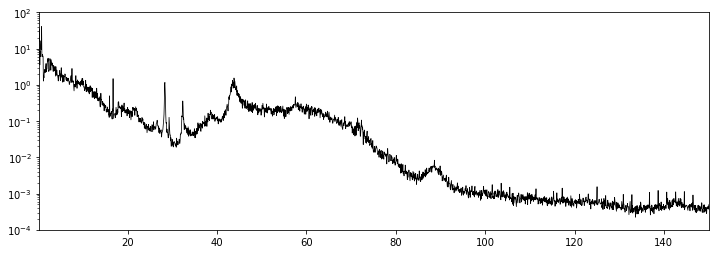

In [9]:
fig0, ax0 = plt.subplots(1,1, figsize=(12, 4), facecolor='w', edgecolor='k')
fig0.subplots_adjust(hspace = 0.5, wspace=.5)
av_periodogram = np.mean(periodogram, axis=0)
plt.semilogy(freq,av_periodogram,'k',lw=0.75); 
plt.xlim(0.1, 150)  
plt.ylim(1e-4, 1e2) 

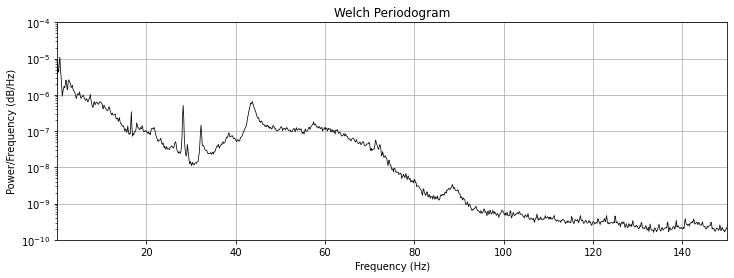

In [12]:
from scipy.signal import welch
frequencies, welch_psd = welch(dataz, fs=fe, nperseg=N/2)
plt.figure(figsize=(12, 4))
plt.semilogy(frequencies, welch_psd,'k',lw=0.75)
plt.xlim(0.1, 150) 
plt.ylim(1e-10, 1e-4) 
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power/Frequency (dB/Hz)')
plt.title('Welch Periodogram')
plt.grid()
plt.show()

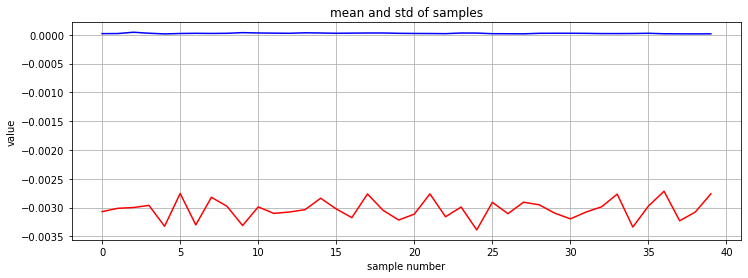

the mean of the long signal is -0.003033243
the variance of the long signal is 2.35073e-05


In [181]:
means = np.zeros(len(segments))
stds = np.zeros(len(segments))
for k in range(M):
    means[k] = np.mean(segments[k])
    stds[k] = np.var(segments[k])

    
plt.figure(figsize=(12, 4))
plt.plot(means,'r')
plt.plot(stds,'b')
plt.xlabel('sample number')
plt.ylabel('value')
plt.title('mean and std of samples')
plt.grid()
plt.show()


mean_str = str(np.mean(dataz))
variance_str = str(np.var(dataz))

print('the mean of the long signal is ' + mean_str)
print('the variance of the long signal is ' + variance_str)



We note that the mean and variance of each sample is almost constant, which is an indication that our random signal can be considered to be ergodic!

2.35073e-05